In [1]:
# Import required libraries
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.ml.classification import (LogisticRegressionModel,RandomForestClassificationModel,OneVsRestModel)
from pyspark.mllib.evaluation import MulticlassMetrics
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (confusion_matrix,roc_curve,auc,precision_recall_curve,average_precision_score)
from sklearn.metrics import (confusion_matrix,ConfusionMatrixDisplay,classification_report)
from sklearn.metrics import ConfusionMatrixDisplay
from pyspark.ml.tuning import (CrossValidator,CrossValidatorModel,ParamGridBuilder)
from xgboost.spark import SparkXGBClassifier
import zipfile
import os
from pyspark.ml.linalg import VectorUDT, Vectors
from pyspark.sql.functions import udf
import shap
import traceback
from pyspark import StorageLevel
from sklearn.metrics import f1_score, balanced_accuracy_score

In [2]:
spark = (SparkSession.builder.appName("NYC_Taxi_Task5").getOrCreate())

In [3]:
# paths of ZIP files
TEST_ZIP = "/content/test_prepared.zip"
with zipfile.ZipFile(TEST_ZIP, "r") as zip_ref:
    zip_ref.extractall("/content/test_prepared")

In [4]:
# path to the prepared test dataset
TEST_PATH = "/content/test_prepared"
if not os.path.isdir(TEST_PATH):
    raise FileNotFoundError("Test dataset not found.")
test_prepared = spark.read.parquet(TEST_PATH)


In [5]:
# Display dataset size and structure
print("Number of test rows:", test_prepared.count())
print("Number of columns:", len(test_prepared.columns))
test_prepared.printSchema()

Number of test rows: 1234316
Number of columns: 2
root
 |-- features: vector (nullable = true)
 |-- label: double (nullable = true)



In [6]:
# inspect a few records from test data
test_prepared.select("label", "features").show(5, truncate=False)

+-----+------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|label|features                                                                                                                                                                                                                      |
+-----+------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|2.0  |(550,[0,2,4,5,8,14,24,44,295],[1.2796361685365383,0.5073004121979604,2.228664870043009,0.2908365368834783,2.3545811223893347,3.3415630662567515,3.3415630662567515,6.676810781821803,6.083931898401993])                      |
|2.0  |(550,[0,2,4,5,7,14,24,45,304],[1.2796361685365383,0.5073004121979604,

In [7]:
# extract the saved models
ZIP_PATH = "/content/models.zip"
EXTRACT_PATH = "/content/models"
with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall("/content")
print("Models extracted successfully")
print("Available model folders:", os.listdir(EXTRACT_PATH))

Models extracted successfully
Available model folders: ['xgboost', 'random_forest', 'lr', 'gradient_boosting']


In [8]:
# Load saved models
lr_model = CrossValidatorModel.load("/content/models/lr")
rf_model = CrossValidatorModel.load("/content/models/random_forest")
gbt_model = CrossValidatorModel.load("/content/models/gradient_boosting")
xgb_model = CrossValidatorModel.load("/content/models/xgboost")
models = {"Logistic Regression": lr_model,"Random Forest": rf_model,"Gradient Boosting": gbt_model,"XGBoost": xgb_model}
print("Loaded models:")
for name in models:
    print("-", name)

Loaded models:
- Logistic Regression
- Random Forest
- Gradient Boosting
- XGBoost


In [9]:
# create evaluators for Spark classification metrics
accuracy_evaluator = MulticlassClassificationEvaluator(labelCol="label",predictionCol="prediction",metricName="accuracy")
precision_evaluator = MulticlassClassificationEvaluator(labelCol="label",predictionCol="prediction",metricName="weightedPrecision")
recall_evaluator = MulticlassClassificationEvaluator(labelCol="label",predictionCol="prediction",metricName="weightedRecall")
f1_evaluator = MulticlassClassificationEvaluator(labelCol="label",predictionCol="prediction",metricName="f1")

In [10]:
# verify feature dimensions
test_feature_size = (test_prepared.select("features").first()["features"].size)
print("Test feature dimensions:", test_feature_size)
print("Test rows:", test_prepared.count())

Test feature dimensions: 550
Test rows: 1234316


In [11]:
# store predictions and evaluation results
predictions_dict = {}
metric_results = []
evaluation_errors = []
for name, model in models.items():
    print(f"Evaluating: {name}")
    predictions = None
    try:
        predictions = model.transform(test_prepared).persist(StorageLevel.DISK_ONLY)
        row_count = predictions.count()
        if row_count == 0:
            raise ValueError("No predictions generated.")
        accuracy = accuracy_evaluator.evaluate(predictions)
        precision = precision_evaluator.evaluate(predictions)
        recall = recall_evaluator.evaluate(predictions)
        weighted_f1 = f1_evaluator.evaluate(predictions)
        sample_pdf = predictions.select("label", "prediction").toPandas()
        y_true = sample_pdf["label"].astype(int)
        y_pred = sample_pdf["prediction"].astype(int)
        macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
        balanced_acc = balanced_accuracy_score(y_true, y_pred)
        predictions_dict[name] = predictions
        predictions = None
        metric_results.append({
            "Model": name,
            "Rows Evaluated": row_count,
            "Accuracy": accuracy,
            "Weighted Precision": precision,
            "Weighted Recall": recall,
            "Weighted F1": weighted_f1,
            "Macro F1": macro_f1,
            "Balanced Accuracy": balanced_acc})
    except Exception as e:
        print(f"FAILED: {name} — {e}")
        evaluation_errors.append({"Model": name, "Error": str(e)})
    finally:
        if predictions is not None:
            predictions.unpersist(blocking=False)
metrics_df = pd.DataFrame(metric_results)
if not metrics_df.empty:
    display(metrics_df.sort_values("Weighted F1", ascending=False).round(4))
errors_df = pd.DataFrame(evaluation_errors)
if not errors_df.empty:
    display(errors_df)

Evaluating: Logistic Regression
Evaluating: Random Forest
Evaluating: Gradient Boosting
Evaluating: XGBoost


,Model,Rows Evaluated,Accuracy,Weighted Precision,Weighted Recall,Weighted F1,Macro F1,Balanced Accuracy
0,Logistic Regression,1234316,0.8401,0.7870,0.8401,0.7738,0.4004,0.4098
3,XGBoost,1234316,0.8395,0.8277,0.8395,0.7677,0.3931,0.4067
2,Gradient Boosting,1234316,0.8390,0.7068,0.8390,0.7664,0.3804,0.4000
1,Random Forest,1234316,0.8390,0.7068,0.8390,0.7664,0.3804,0.4000


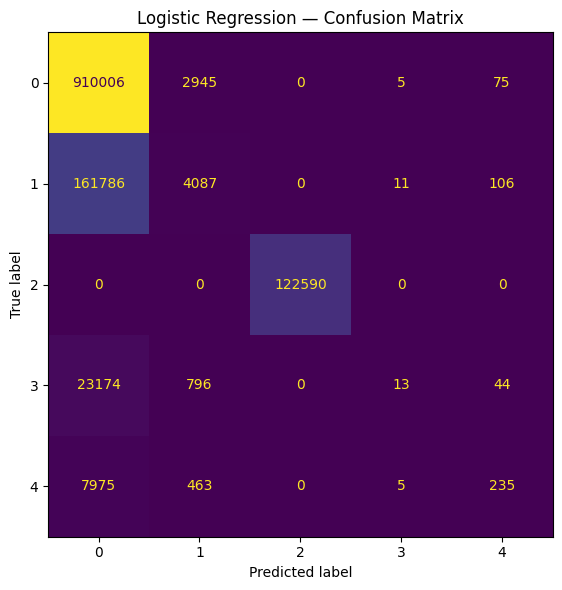

Classification report: Logistic Regression
              precision    recall  f1-score   support

           0       0.83      1.00      0.90    913031
           1       0.49      0.02      0.05    165990
           2       1.00      1.00      1.00    122590
           3       0.38      0.00      0.00     24027
           4       0.51      0.03      0.05      8678

    accuracy                           0.84   1234316
   macro avg       0.64      0.41      0.40   1234316
weighted avg       0.79      0.84      0.77   1234316



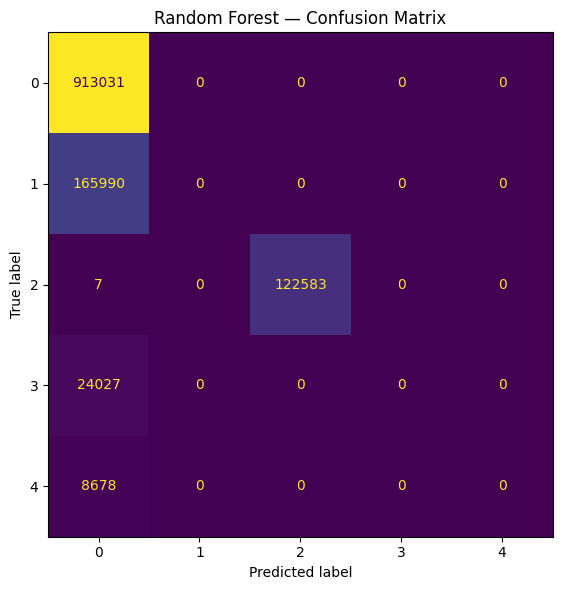

Classification report: Random Forest
              precision    recall  f1-score   support

           0       0.82      1.00      0.90    913031
           1       0.00      0.00      0.00    165990
           2       1.00      1.00      1.00    122590
           3       0.00      0.00      0.00     24027
           4       0.00      0.00      0.00      8678

    accuracy                           0.84   1234316
   macro avg       0.36      0.40      0.38   1234316
weighted avg       0.71      0.84      0.77   1234316



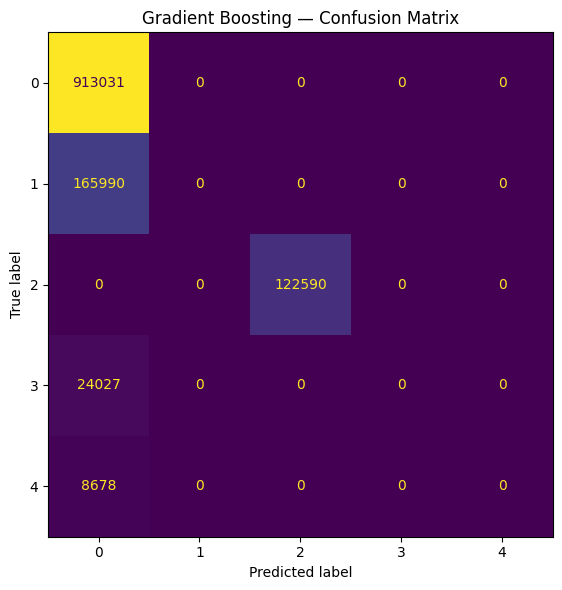

Classification report: Gradient Boosting
              precision    recall  f1-score   support

           0       0.82      1.00      0.90    913031
           1       0.00      0.00      0.00    165990
           2       1.00      1.00      1.00    122590
           3       0.00      0.00      0.00     24027
           4       0.00      0.00      0.00      8678

    accuracy                           0.84   1234316
   macro avg       0.36      0.40      0.38   1234316
weighted avg       0.71      0.84      0.77   1234316



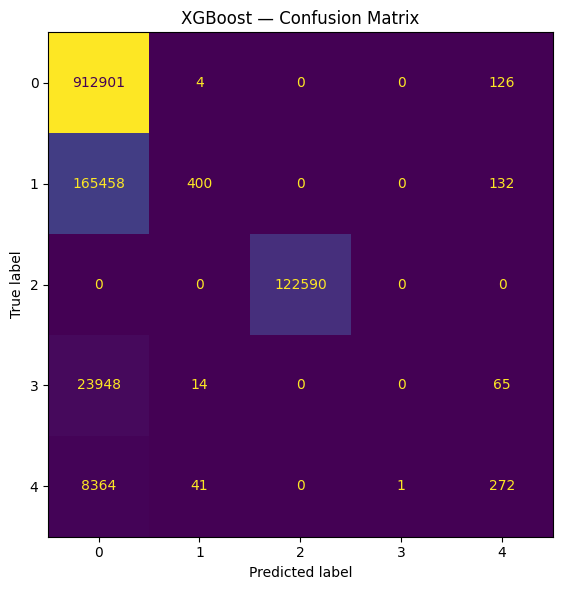

Classification report: XGBoost
              precision    recall  f1-score   support

           0       0.82      1.00      0.90    913031
           1       0.87      0.00      0.00    165990
           2       1.00      1.00      1.00    122590
           3       0.00      0.00      0.00     24027
           4       0.46      0.03      0.06      8678

    accuracy                           0.84   1234316
   macro avg       0.63      0.41      0.39   1234316
weighted avg       0.83      0.84      0.77   1234316



In [12]:
# Plot confusion matrices for all four models
for name, predictions in predictions_dict.items():
    pdf = (predictions.select("label", "prediction").toPandas())
    pdf = pdf.dropna(subset=["label", "prediction"])
    y_true = pdf["label"].astype(int)
    y_pred = pdf["prediction"].astype(int)
    labels = sorted(set(y_true) | set(y_pred))
    cm = confusion_matrix(y_true,y_pred,labels=labels)
    fig, ax = plt.subplots(figsize=(7, 6))
    display_matrix = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=labels)
    display_matrix.plot(ax=ax,values_format="d",colorbar=False)
    ax.set_title(f"{name} — Confusion Matrix")
    plt.tight_layout()
    plt.show()
    print(f"Classification report: {name}")
    print(classification_report(y_true,y_pred,zero_division=0))

In [13]:
# check whether each model returns class probabilities
for name, predictions in predictions_dict.items():
    print(f"\nModel: {name}")
    if "probability" in predictions.columns:
        print("Probability column is available.")
    else:
        print("Probability column is NOT available.")
    predictions.printSchema()


Model: Logistic Regression
Probability column is available.
root
 |-- features: vector (nullable = true)
 |-- label: double (nullable = true)
 |-- rawPrediction: vector (nullable = true)
 |-- probability: vector (nullable = true)
 |-- prediction: double (nullable = false)


Model: Random Forest
Probability column is available.
root
 |-- features: vector (nullable = true)
 |-- label: double (nullable = true)
 |-- rawPrediction: vector (nullable = true)
 |-- probability: vector (nullable = true)
 |-- prediction: double (nullable = false)


Model: Gradient Boosting
Probability column is NOT available.
root
 |-- features: vector (nullable = true)
 |-- label: double (nullable = true)
 |-- rawPrediction: vector (nullable = true)
 |-- prediction: double (nullable = true)


Model: XGBoost
Probability column is available.
root
 |-- features: vector (nullable = true)
 |-- label: double (nullable = true)
 |-- rawPrediction: vector (nullable = true)
 |-- prediction: double (nullable = true)
 |-- 

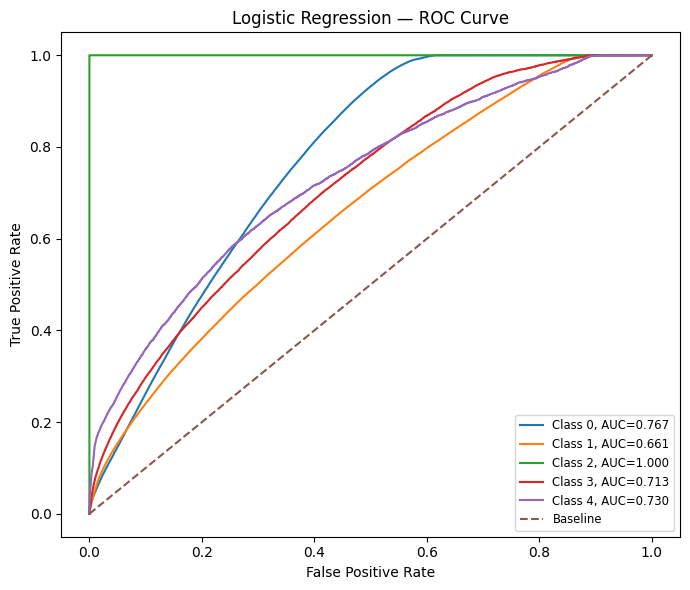

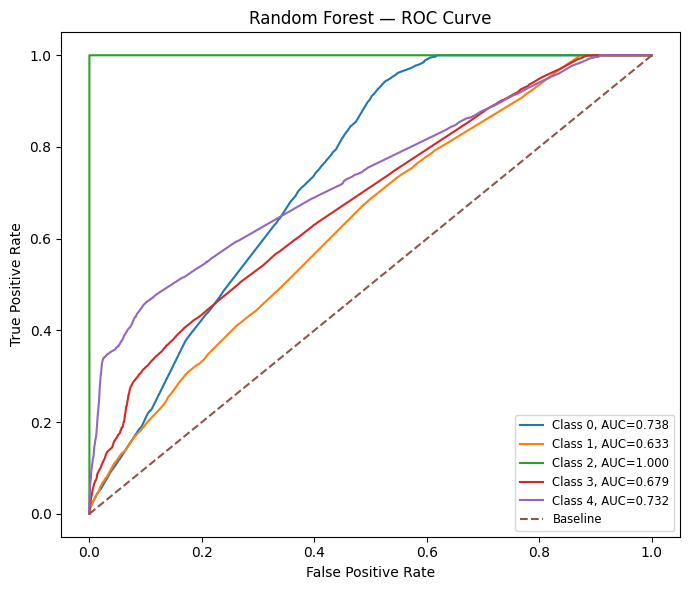

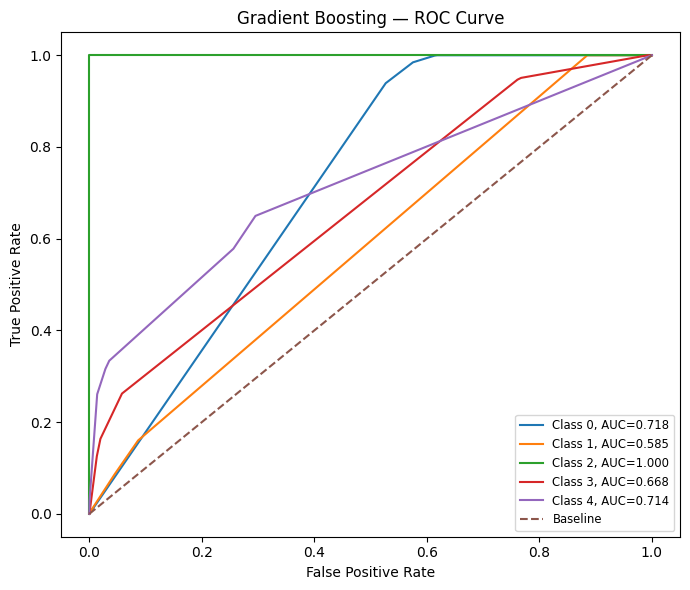

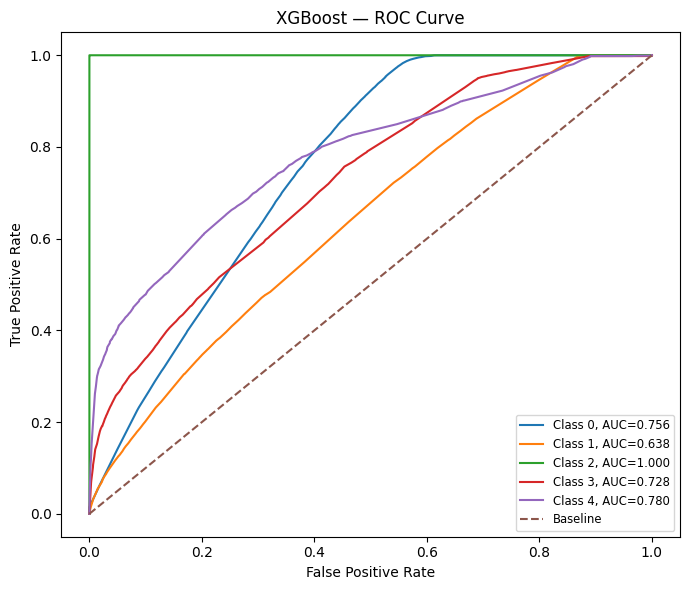

In [14]:
# plot ROC curves and calculate AUC
roc_results = []
for name, predictions in predictions_dict.items():
    score_col = "probability" if "probability" in predictions.columns else "rawPrediction"
    pdf = predictions.select("label", score_col).dropna().toPandas()
    if pdf.empty:
        continue
    y_true = pdf["label"].astype(int).to_numpy()
    scores = np.vstack([v.toArray() for v in pdf[score_col]])
    fig, ax = plt.subplots(figsize=(7, 6))
    for class_id in range(scores.shape[1]):
        y_binary = (y_true == class_id).astype(int)
        if len(np.unique(y_binary)) < 2:
            continue
        fpr, tpr, _ = roc_curve(y_binary, scores[:, class_id])
        class_auc = auc(fpr, tpr)
        roc_results.append({"Model": name, "Class": class_id, "AUC": class_auc})
        ax.plot(fpr, tpr, label=f"Class {class_id}, AUC={class_auc:.3f}")
    ax.plot([0, 1], [0, 1], "--", label="Baseline")
    ax.set(title=f"{name} — ROC Curve",
           xlabel="False Positive Rate", ylabel="True Positive Rate")
    ax.legend(fontsize="small")
    plt.tight_layout()
    plt.show()
    print("\n")
roc_df = pd.DataFrame(roc_results)

/tmp/ipykernel_5330/2140879783.py:21: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


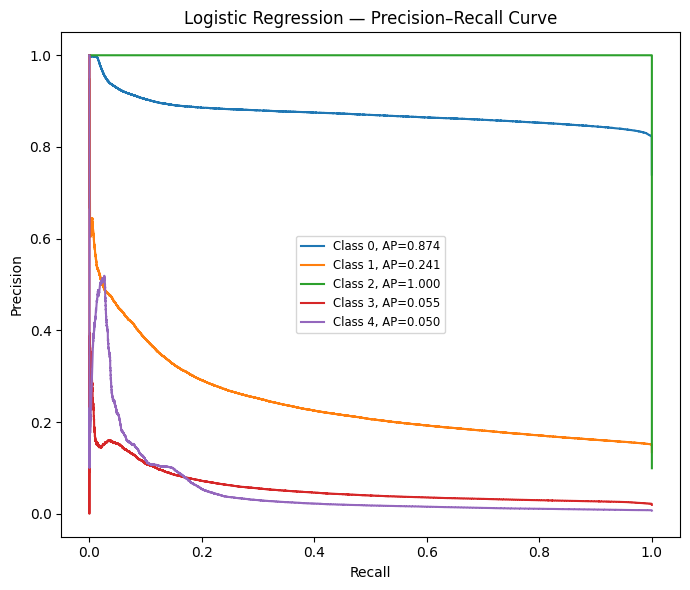

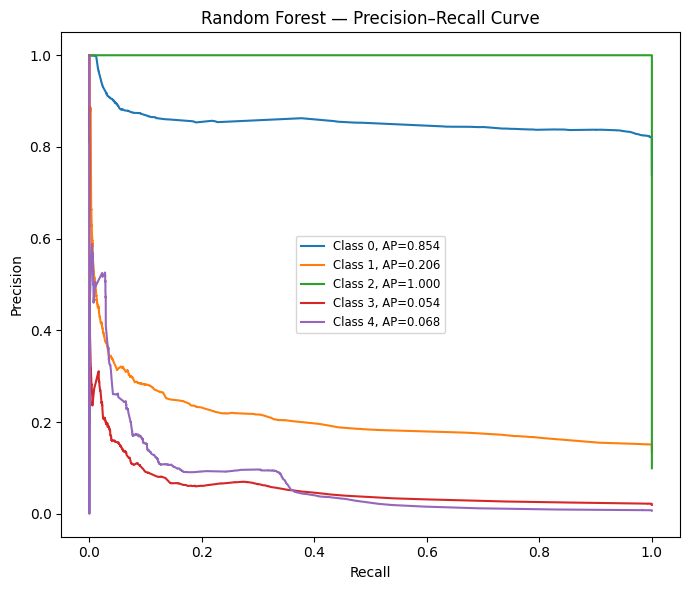

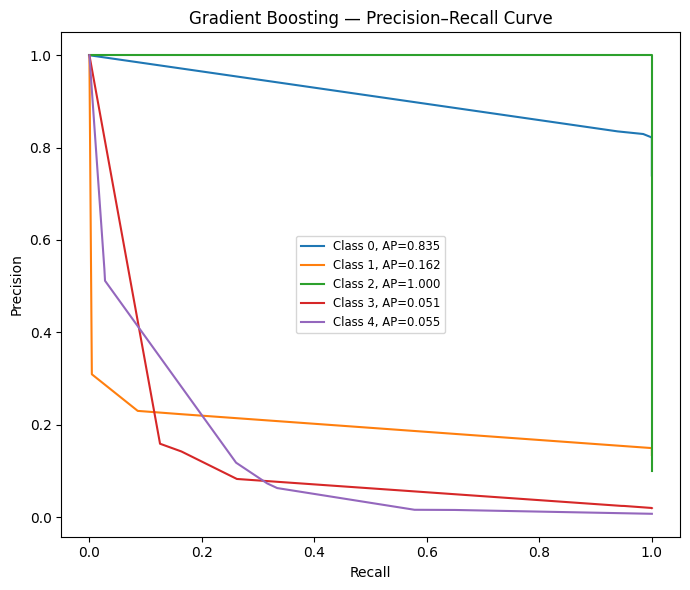

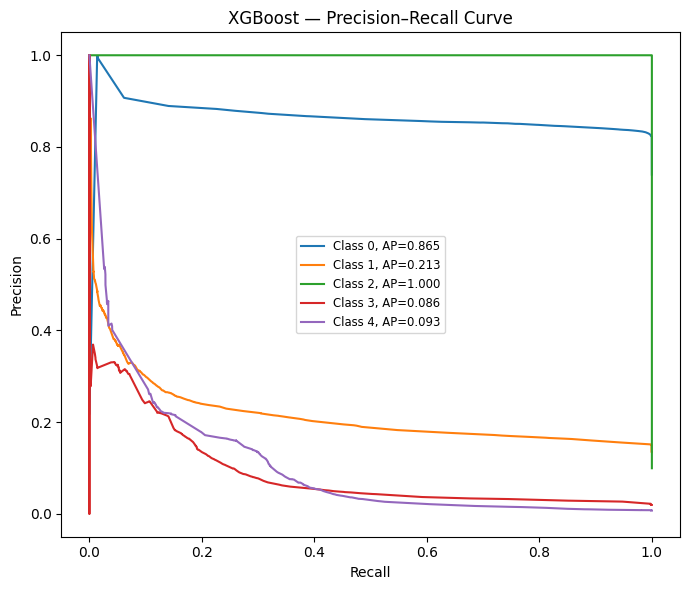

,Model,Class,Average Precision
0,Logistic Regression,0,0.8737
1,Logistic Regression,1,0.2405
2,Logistic Regression,2,1.0000
3,Logistic Regression,3,0.0554
4,Logistic Regression,4,0.0502
5,Random Forest,0,0.8543
6,Random Forest,1,0.2063
7,Random Forest,2,1.0000
8,Random Forest,3,0.0539
9,Random Forest,4,0.0675


In [15]:
# plot pr curves
pr_results = []
for name, predictions in predictions_dict.items():
    score_col = "probability" if "probability" in predictions.columns else "rawPrediction"
    pdf = predictions.select("label", score_col).dropna().toPandas()
    if pdf.empty:
        continue
    y_true = pdf["label"].astype(int).to_numpy()
    scores = np.vstack([v.toArray() for v in pdf[score_col]])
    fig, ax = plt.subplots(figsize=(7, 6))
    for class_id in range(scores.shape[1]):
        y_binary = (y_true == class_id).astype(int)
        if len(np.unique(y_binary)) < 2:
            continue
        precision, recall, _ = precision_recall_curve(y_binary, scores[:, class_id])
        ap = average_precision_score(y_binary, scores[:, class_id])
        pr_results.append({"Model": name, "Class": class_id, "Average Precision": ap})
        ax.plot(recall, precision, label=f"Class {class_id}, AP={ap:.3f}")
    ax.set(title=f"{name} — Precision–Recall Curve", xlabel="Recall", ylabel="Precision")
    ax.legend(fontsize="small")
    plt.tight_layout()
    plt.show()
    print("\n")
pr_df = pd.DataFrame(pr_results)
display(pr_df.round(4))

In [16]:
RANDOM_SEED = 42
STABILITY_SAMPLE_FRACTION = 0.01
PERTURBATION_STD = 0.01

In [17]:
# perturbation stability analysis
stability_sample = (test_prepared.sample(withReplacement=False,fraction=STABILITY_SAMPLE_FRACTION,seed=RANDOM_SEED).withColumn("_row_id", F.monotonically_increasing_id()).persist(StorageLevel.MEMORY_AND_DISK))
sample_count = stability_sample.count()
print("rows used for stability analysis:", sample_count)
if sample_count == 0:
    raise ValueError("The stability sample is empty")

rows used for stability analysis: 12435


In [18]:
# function adds Gaussian noise to feature values.
def perturb_vector(vector, row_id):
    if vector is None or row_id is None:
        return None
    values = np.asarray(vector.toArray(), dtype=float)
    rng = np.random.default_rng(RANDOM_SEED + int(row_id))
    noise = rng.normal(loc=0.0,scale=PERTURBATION_STD,size=values.shape)
    return Vectors.dense(values + noise)
perturb_udf = udf(perturb_vector, VectorUDT())

In [19]:
# create perturbed features while retaining row ID
perturbed_input = (stability_sample.withColumn("features",perturb_udf(F.col("features"), F.col("_row_id"))).persist(StorageLevel.MEMORY_AND_DISK))
perturbed_input.count()
print("Perturbed test sample created")

Perturbed test sample created


In [20]:
# compare original and perturbed predictions
stability_results = []
for name, model in models.items():
    print("Analysing:", name)
    original_predictions = (model.transform(stability_sample).select("_row_id",F.col("prediction").alias("original_prediction")))
    perturbed_predictions = (model.transform(perturbed_input).select("_row_id",F.col("prediction").alias("perturbed_prediction")))
    paired = original_predictions.join(perturbed_predictions,on="_row_id",how="inner")
    comparison = paired.agg(F.avg(F.when(F.col("original_prediction") == F.col("perturbed_prediction"),1.0).otherwise(0.0)).alias("prediction_stability"),F.count("*").alias("rows_compared")).first()
    stability = comparison["prediction_stability"]
    stability_results.append({"Model": name,"Prediction Stability": stability,"Prediction Change Rate": (1.0 - stability if stability is not None else None),
        "Rows Compared": comparison["rows_compared"]})
stability_df = pd.DataFrame(stability_results)
display(stability_df.round(4))

Analysing: Logistic Regression
Analysing: Random Forest
Analysing: Gradient Boosting
Analysing: XGBoost


,Model,Prediction Stability,Prediction Change Rate,Rows Compared
0,Logistic Regression,0.9999,0.0001,12435
1,Random Forest,1.0000,0.0000,12435
2,Gradient Boosting,1.0000,0.0000,12435
3,XGBoost,0.9479,0.0521,12435


In [22]:
# metric results comparision table
metrics_df = pd.DataFrame(metric_results)
required_models = {"Logistic Regression","Random Forest","Gradient Boosting","XGBoost"}
metric_columns = [
        "Accuracy",
        "Weighted Precision",
        "Weighted Recall",
        "Weighted F1",
        "Macro F1",
        "Balanced Accuracy"]
required_columns = ["Model", "Rows Evaluated"] + metric_columns
comparison_df = (metrics_df[required_columns].sort_values("Weighted F1", ascending=False).reset_index(drop=True))
display(comparison_df.round(4))

,Model,Rows Evaluated,Accuracy,Weighted Precision,Weighted Recall,Weighted F1,Macro F1,Balanced Accuracy
0,Logistic Regression,1234316,0.8401,0.7870,0.8401,0.7738,0.4004,0.4098
1,XGBoost,1234316,0.8395,0.8277,0.8395,0.7677,0.3931,0.4067
2,Gradient Boosting,1234316,0.8390,0.7068,0.8390,0.7664,0.3804,0.4000
3,Random Forest,1234316,0.8390,0.7068,0.8390,0.7664,0.3804,0.4000


In [23]:
# Explainability using Logistic Regression coefficients
lr_best_model = lr_model.bestModel
coefficient_matrix = lr_best_model.coefficientMatrix.toArray()
importance_values = np.mean(np.abs(coefficient_matrix), axis=0)
feature_metadata = test_prepared.schema["features"].metadata
ml_attributes = feature_metadata.get("ml_attr", {}).get("attrs", {})
feature_names = [None] * len(importance_values)
for attribute_group in ml_attributes.values():
    for attribute in attribute_group:
        index = attribute.get("idx")
        name = attribute.get("name")
        if index is not None and name is not None:
            if 0 <= index < len(feature_names):
                feature_names[index] = name
missing_names = [i for i, name in enumerate(feature_names) if name is None]
if missing_names:
    feature_names = [
        name if name is not None else f"Feature_{i}"
        for i, name in enumerate(feature_names)]
# Verify dimensions
assert len(feature_names) == len(importance_values)

In [24]:
# Create the feature importance table
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values})
importance_df = (importance_df.sort_values("Importance", ascending=False).reset_index(drop=True))
display(importance_df.head(15))

,Feature,Importance
0,Feature_24,0.244202
1,Feature_14,0.244202
2,Feature_23,0.235183
3,Feature_13,0.174592
4,Feature_16,0.091787
5,Feature_8,0.063366
6,Feature_7,0.063341
7,Feature_28,0.061592
8,Feature_6,0.058008
9,Feature_321,0.041993


In [25]:
# Create the feature importance table
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values})
importance_df = (importance_df.sort_values("Importance", ascending=False).reset_index(drop=True))
display(importance_df.head(15))

,Feature,Importance
0,Feature_24,0.244202
1,Feature_14,0.244202
2,Feature_23,0.235183
3,Feature_13,0.174592
4,Feature_16,0.091787
5,Feature_8,0.063366
6,Feature_7,0.063341
7,Feature_28,0.061592
8,Feature_6,0.058008
9,Feature_321,0.041993


In [26]:
# Check feature metadata
feature_metadata = test_prepared.schema["features"].metadata
print(feature_metadata)

{'ml_attr': {'num_attrs': 550}}


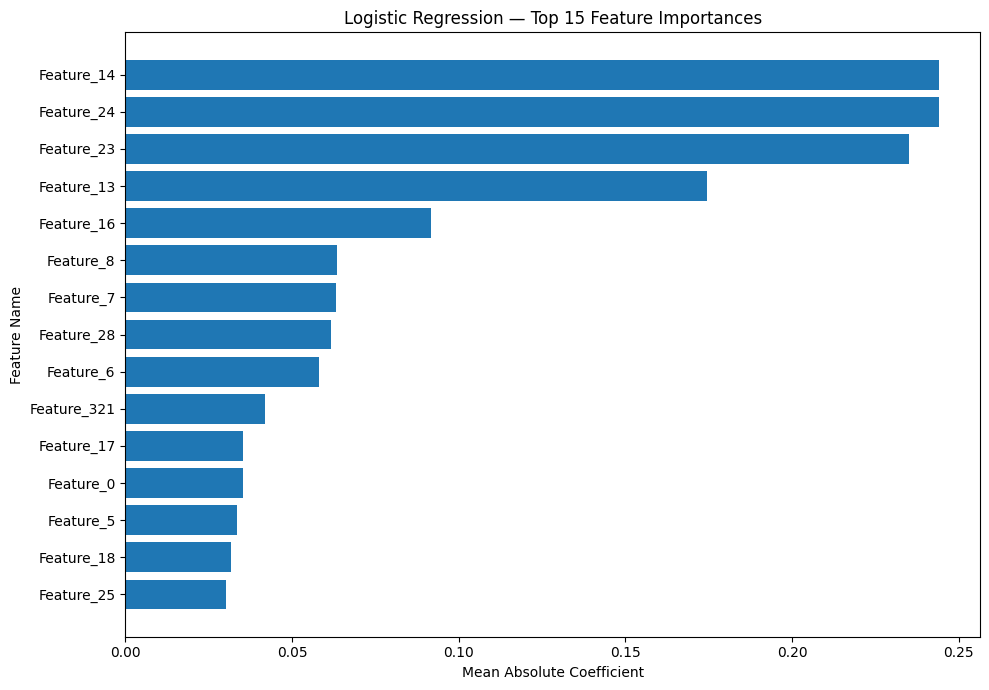

In [27]:
# plot the feature importance
top_features = (importance_df.head(15).sort_values("Importance", ascending=True))
plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"],top_features["Importance"])
plt.xlabel("Mean Absolute Coefficient")
plt.ylabel("Feature Name")
plt.title("Logistic Regression — Top 15 Feature Importances")
plt.tight_layout()
plt.show()

In [28]:
# Select a small sample from the test dataset
shap_data = (test_prepared.select("features").limit(50).toPandas())

In [29]:
# Convert Spark feature vectors into a NumPy array
X = np.array([v.toArray() for v in shap_data["features"]])

In [30]:
# Explainability using SHAP for logistic Regression
background = X[:20]
X_explain = X[20:50]
TARGET_CLASS = 1
def predict_lr_class_probability(data):
    data = np.asarray(data, dtype=float)
    spark_data = spark.createDataFrame([(Vectors.dense(row),) for row in data],["features"])
    predictions = lr_best_model.transform(spark_data)
    probabilities = np.vstack([
        vector.toArray()
        for vector in predictions.select("probability")
        .toPandas()["probability"]])
    return probabilities[:, TARGET_CLASS]

  0%|          | 0/30 [00:00<?, ?it/s]

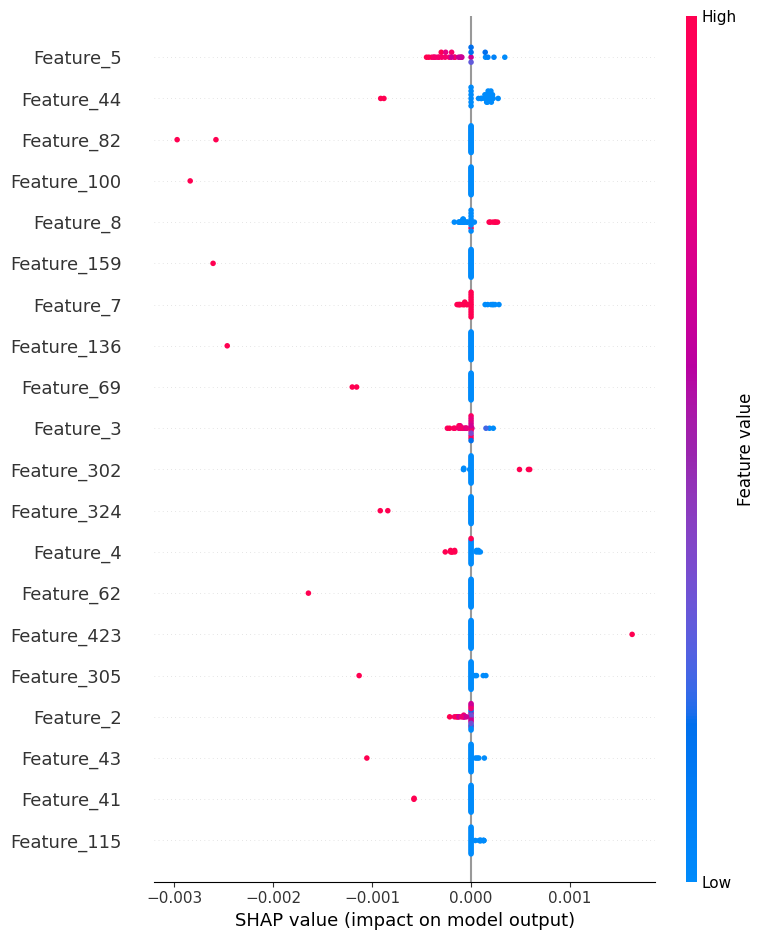

In [31]:
# summary plot for logistic regression
explainer = shap.KernelExplainer(predict_lr_class_probability,background)
shap_values = explainer.shap_values(X_explain,nsamples=100)
shap.summary_plot(shap_values,X_explain,feature_names=feature_names,max_display=20)

In [32]:
# export the result
metrics_df.to_csv("/content/task5_metrics_comparison.csv",index=False)
stability_df.to_csv("/content/task5_stability.csv",index=False)
importance_df.to_csv("/content/task5_logistic_regression_feature_importance.csv",index=False)
roc_df.to_csv("/content/task5_roc_results.csv", index=False)
pr_df.to_csv("/content/task5_precision_recall_results.csv", index=False)